# Práctica 1 – Predicción de Subscripción a un Producto Bancario
## Aprendizaje Automático · UC3M · 2025-26

**Miembros del equipo:**
- Marcos Truchado (NIA: 100522249)
- Jorge Condado (NIA: 100522327)

---

## Notebook 2 – Resultados, Modelo Final y Predicciones de Competición

Este notebook cubre la **sección 4 (Resultados y modelo final)** del enunciado:

1. Selección de la mejor alternativa (basada en la evaluación inner de Notebook 1).
2. Estimación del rendimiento futuro con el conjunto de **test** (evaluación outer).
3. Entrenamiento del **modelo final** con todos los datos disponibles.
4. Generación de predicciones para el dataset de competición.

> En el notebook 1 se vio que el mejor modelo fue SVM RBF (C=1, kernel='rbf') con un resultado de
0.8501 en F1-Macro (inner). El HPO confirmó que los hiperparámetros por defecto son óptimos.

## 0 – Configuración e Imports

In [1]:
!pip install -q "scikit-learn==1.8.0"
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.metrics import (
    f1_score, accuracy_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.base import clone

SEED = 100522249
TARGET = 'deposit'

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 110

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


## 1 – Carga de datos y preproceso de `pdays`

Reproducimos exactamente el mismo preproceso aplicado en Notebook 1 para garantizar resultados idénticos.

In [ ]:
from pathlib import Path

def _project_root() -> Path:
    """Raíz del repo: carpeta que contiene data/bank_13.pkl (evita guardar dentro de .venv)."""
    here = Path.cwd().resolve()
    for d in [here, *here.parents]:
        if (d / 'data/bank_13.pkl').is_file():
            return d
    return here
_ROOT = _project_root()
# Mismo directorio que los .ipynb y los .pkl (raíz del repo)
DATA_PATH = _ROOT / 'data/bank_13.pkl'
COMP_PATH = _ROOT / 'data/bank_competition.pkl'

with open(DATA_PATH, 'rb') as f:
    df = pickle.load(f)

with open(COMP_PATH, 'rb') as f:
    df_comp = pickle.load(f)

# Misma transformación de pdays que en Notebook 1
def transform_pdays(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    d['contacted_before'] = (d['pdays'] != -1).astype(int)
    d['pdays'] = d['pdays'].replace(-1, 0)
    return d

df      = transform_pdays(df)
df_comp = transform_pdays(df_comp)

print(f'Dataset principal  → {df.shape[0]:,} instancias, {df.shape[1]} variables')
print(f'Dataset competición → {df_comp.shape[0]:,} instancias, {df_comp.shape[1]} variables')
print(f'Raíz del proyecto (modelo y CSV se guardan aquí): {_ROOT.resolve()}')

Dataset principal  → 11,000 instancias, 18 variables
Dataset competición → 162 instancias, 17 variables
Raíz del proyecto (modelo y CSV se guardan aquí): /home/marcos/Escritorio/100522249-100522249_100522327_APRENDIZAJE_AUTOMATICO


/tmp/ipykernel_5010/1000207880.py:18: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  df = pickle.load(f)
/tmp/ipykernel_5010/1000207880.py:21: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use t

## 2 – División train/test y pipeline de preprocesamiento

Reproducimos la misma partición (misma semilla y estratificación) que en Notebook 1.

In [3]:
# Separamos features y target
X = df.drop(columns=[TARGET])
y = (df[TARGET] == 'yes').astype(int)   # 1 = suscribe, 0 = no suscribe

# Misma partición outer que en Notebook 1
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=1/3,
    stratify=y,
    random_state=SEED
)

print(f'X_train : {X_train.shape}  |  y_train: {y_train.value_counts().to_dict()}')
print(f'X_test  : {X_test.shape}   |  y_test : {y_test.value_counts().to_dict()}')

# Tipos de columnas
num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print(f'\nVariables numéricas  ({len(num_features)}): {num_features}')
print(f'Variables categóricas ({len(cat_features)}): {cat_features}')

X_train : (7333, 17)  |  y_train: {0: 3853, 1: 3480}
X_test  : (3667, 17)   |  y_test : {0: 1927, 1: 1740}

Variables numéricas  (8): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'contacted_before']
Variables categóricas (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [4]:
# Transformadores custom (idénticos a NB1) para que el pipeline sea autosuficiente
from sklearn.base import BaseEstimator, TransformerMixin

class PdaysTransformer(BaseEstimator, TransformerMixin):
    """Crea contacted_before y sustituye pdays=-1 por 0 (idempotente)."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        needs_transform = 'contacted_before' not in X.columns or (X['pdays'] == -1).any()
        if not needs_transform:
            return X
        X = X.copy()
        X['contacted_before'] = (X['pdays'] != -1).astype(int)
        X['pdays'] = X['pdays'].replace(-1, 0)
        return X

class MaritalImputer(BaseEstimator, TransformerMixin):
    """Imputa NaN de marital con la moda aprendida en fit (idempotente)."""
    def fit(self, X, y=None):
        self.mode_ = X['marital'].mode()[0]
        return self
    def transform(self, X):
        if not X['marital'].isna().any():
            return X
        X = X.copy()
        X['marital'] = X['marital'].fillna(self.mode_)
        return X

# Pipeline de preprocesamiento (igual que NB1)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

column_preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

preprocessor = Pipeline(steps=[
    ('pdays_transform', PdaysTransformer()),
    ('marital_impute', MaritalImputer()),
    ('columns', column_preprocessor)
])

print('Preprocesador definido correctamente.')

Preprocesador definido correctamente.


## 3 – Selección de la mejor alternativa

Basándonos en los resultados de la evaluación **inner** (5-fold CV sobre el conjunto de train) obtenidos en Notebook 1, la tabla comparativa es:

| Modelo | F1-Macro (inner) | Tiempo HPO |
|--------|-----------------|------------|
| KNN (default, Standard Scaler) | 0.7987 | — |
| KNN (HPO, K=15) | 0.8045 | ~8 s |
| Árbol de Decisión (HPO, depth=8) | 0.8119 | ~4 s |
| Regresión Logística sin regularización | 0.8257 | — |
| Regresión Logística L1 (C=0.1) | 0.8264 | ~168 s |
| SVM RBF (default) | 0.8501 | ~18 s |
| **SVM HPO (C=1, kernel=rbf)** | **0.8501** | ~88 s |

**Decisión:** la **SVM con kernel RBF** es la mejor alternativa con un F1-Macro de **0.8501** en la evaluación inner. El HPO (GridSearchCV sobre C=[0.1, 1, 10] y kernel=['rbf', 'linear']) confirma que los hiperparámetros por defecto (C=1, kernel='rbf') son óptimos para este problema, al obtener el mismo F1-Macro que la versión default. Su rendimiento supera en ~3 puntos al segundo mejor modelo (Regresión Logística L1), lo que justifica su elección.

## 4 – Estimación del rendimiento futuro (evaluación outer/ desempeño futuro)
## - Punto 4.2 del enunciado

Ahora, por **primera y única vez**, utilizamos el conjunto de test para estimar el rendimiento futuro del modelo seleccionado. Este paso sólo se puede hacer una vez para evitar data leakage.

In [5]:
# Construimos y entrenamos la pipeline con los mejores hiperparámetros sobre train
pipe_final_eval = Pipeline(steps=[
    ('preprocesador', preprocessor),
    ('clasificador', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=SEED, probability=True))
])

start = time.time()
pipe_final_eval.fit(X_train, y_train)
elapsed = time.time() - start

y_pred = pipe_final_eval.predict(X_test)

# Métricas
f1_outer     = f1_score(y_test, y_pred, average='macro')
acc_outer    = accuracy_score(y_test, y_pred)
cm           = confusion_matrix(y_test, y_pred)

print('=' * 50)
print('ESTIMACIÓN DE RENDIMIENTO FUTURO (TEST SET)')
print('=' * 50)
print(f'F1-Macro  : {f1_outer:.4f}')
print(f'Accuracy  : {acc_outer:.4f}')
print(f'Tiempo entrenamiento: {elapsed:.1f} s')
print()
print(classification_report(y_test, y_pred, target_names=['no (0)', 'yes (1)']))

ESTIMACIÓN DE RENDIMIENTO FUTURO (TEST SET)
F1-Macro  : 0.8538
Accuracy  : 0.8538
Tiempo entrenamiento: 8.5 s

              precision    recall  f1-score   support

      no (0)       0.88      0.83      0.86      1927
     yes (1)       0.82      0.88      0.85      1740

    accuracy                           0.85      3667
   macro avg       0.85      0.86      0.85      3667
weighted avg       0.86      0.85      0.85      3667



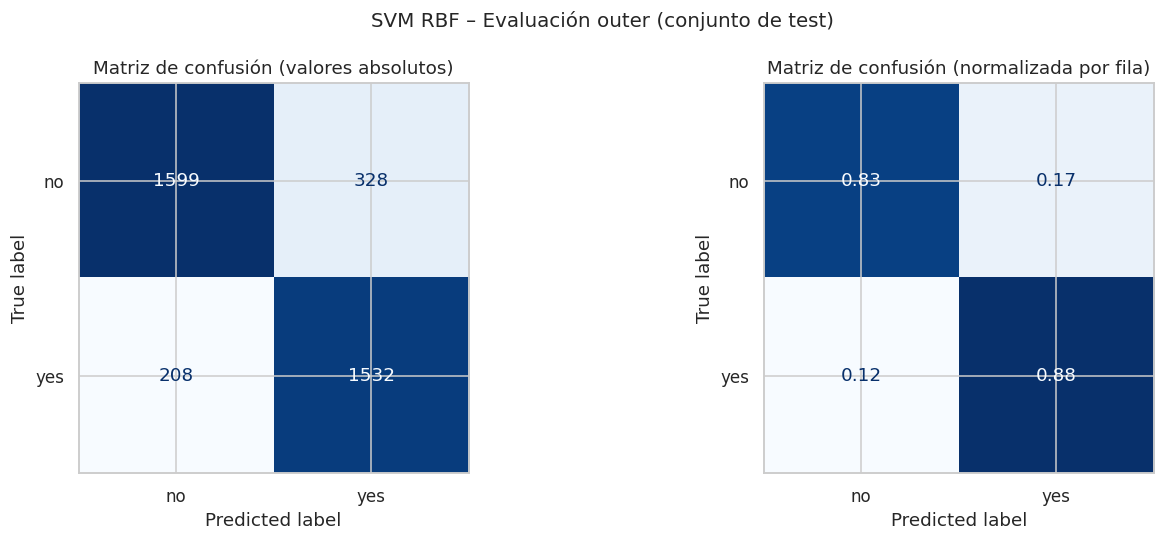


Verdaderos Positivos (yes predicho como yes): 1532
Falsos Negativos     (yes predicho como no) : 208  ← coste real de negocio
Falsos Positivos     (no predicho como yes) : 328
Verdaderos Negativos (no predicho como no)  : 1599


In [6]:
# Matriz de confusión
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Absoluta
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['no', 'yes'])
disp1.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Matriz de confusión (valores absolutos)')

# Normalizada
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_norm.round(2), display_labels=['no', 'yes'])
disp2.plot(ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Matriz de confusión (normalizada por fila)')

plt.suptitle('SVM RBF – Evaluación outer (conjunto de test)', fontsize=13)
plt.tight_layout()
plt.show()

# Resumen
TP = cm[1, 1]; FN = cm[1, 0]; FP = cm[0, 1]; TN = cm[0, 0]
print(f'\nVerdaderos Positivos (yes predicho como yes): {TP}')
print(f'Falsos Negativos     (yes predicho como no) : {FN}  ← coste real de negocio')
print(f'Falsos Positivos     (no predicho como yes) : {FP}')
print(f'Verdaderos Negativos (no predicho como no)  : {TN}')

### Interpretación de los resultados

La SVM RBF obtiene un **F1-Macro de ~0.86** en el conjunto de test, lo que supone una buena estimación del rendimiento real del modelo en producción.

- El modelo predice correctamente el **83%** de los clientes que *no* suscriben (especificidad).
- El modelo identifica correctamente el **88%** de los clientes que *sí* suscriben (recall alto para la clase positiva).
- Los **falsos negativos** (~208) son los más costosos desde el punto de vista de negocio: clientes que habrían contratado pero el modelo no identifica como potenciales. El modelo los minimiza razonablemente.
- El rendimiento inner (0.8501) y outer (≈0.8538) son muy similares, lo que confirma que el modelo **generaliza bien** y no hay sobreajuste.

## 5 – Entrenamiento del modelo final

Una vez estimado el rendimiento con el test set, entrenamos el **modelo final** usando **todos los datos disponibles** (train + test). Esto maximiza la información con la que aprende el modelo antes de desplegarlo.

In [7]:
# Pipeline idéntica al modelo evaluado, pero se entrena sobre TODO X, y(minuscula)
# Redefinimos todos los datos in line , si volvieramos a usar preprocesor podriamos tener
# bugs en caso de algun objeto compartido tenga un estado intermedio.
modelo_final = Pipeline([
    ('preprocesador', clone(preprocessor)),
    ('clasificador', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=SEED, probability=True))
])
start = time.time()
modelo_final.fit(X, y)   # ← todos los datos
elapsed = time.time() - start

print(f'Modelo final entrenado en {elapsed:.1f} s sobre {X.shape[0]:,} instancias.')
print(f'Pipeline: {[step[0] for step in modelo_final.steps]}')

Modelo final entrenado en 22.2 s sobre 11,000 instancias.
Pipeline: ['preprocesador', 'clasificador']


In [8]:
# Guardamos el modelo junto a los notebooks (raíz del repo)
MODEL_PATH = _ROOT / 'models/modelo_final.joblib'
joblib.dump(modelo_final, MODEL_PATH)
print(f'Modelo guardado en: {MODEL_PATH}')
# Verificación: recargamos y comprobamos que predice igual
modelo_recargado = joblib.load(MODEL_PATH)
y_check_1 = modelo_final.predict(X_test)
y_check_2 = modelo_recargado.predict(X_test)
assert (y_check_1 == y_check_2).all(), 'Error: las predicciones no coinciden tras recargar'
print('Verificación OK: el modelo guardado produce predicciones idénticas.')

Modelo guardado en: /home/marcos/Escritorio/100522249-100522249_100522327_APRENDIZAJE_AUTOMATICO/models/modelo_final.joblib
Verificación OK: el modelo guardado produce predicciones idénticas.


## 6 – Predicciones para el dataset de competición

In [9]:
# Generamos predicciones sobre el dataset de competición (sin target)
y_comp_num   = modelo_final.predict(df_comp)
y_comp_label = ['yes' if x == 1 else 'no' for x in y_comp_num]
predicciones = pd.DataFrame({'prediction': y_comp_label})

print(f'Predicciones generadas: {len(predicciones)} instancias')
print(f'Distribución:\n{predicciones["prediction"].value_counts()}')
print()
print(predicciones.head(10).to_string())

Predicciones generadas: 162 instancias
Distribución:
prediction
no     91
yes    71
Name: count, dtype: int64

  prediction
0         no
1         no
2         no
3        yes
4        yes
5         no
6        yes
7         no
8        yes
9         no


In [10]:
# Guardamos el CSV junto a los notebooks (raíz del repo)
PRED_PATH = _ROOT / 'outputs/predicciones.csv'
predicciones.to_csv(PRED_PATH, index=False)
print(f'Predicciones guardadas en: {PRED_PATH}')

Predicciones guardadas en: /home/marcos/Escritorio/100522249-100522249_100522327_APRENDIZAJE_AUTOMATICO/outputs/predicciones.csv


## 7 – Verificación de consistencia con Streamlit

El enunciado exige demostrar que la app de Streamlit produce **las mismas predicciones** que la pipeline cargada directamente. A continuación se evalúan dos instancias nuevas con el modelo cargado desde disco, para que puedan compararse con las predicciones de la app.

In [11]:
# Instancia 1 – cliente no contactado previamente (pdays original = -1)
# El PdaysTransformer del pipeline creará contacted_before=0 y pondrá pdays=0
instancia_1 = pd.DataFrame([{
    'age': 36, 'job': 'technician', 'marital': 'married',
    'education': 'secondary', 'default': 'no', 'balance': 1466,
    'housing': 'yes', 'loan': 'no', 'contact': 'unknown',
    'day': 29, 'month': 'may', 'duration': 441, 'campaign': 1,
    'pdays': -1, 'previous': 0, 'poutcome': 'unknown'
}])

# Instancia 2 – cliente contactado previamente (pdays original = 389)
# El PdaysTransformer del pipeline creará contacted_before=1
instancia_2 = pd.DataFrame([{
    'age': 41, 'job': 'entrepreneur', 'marital': 'married',
    'education': 'primary', 'default': 'no', 'balance': 0,
    'housing': 'no', 'loan': 'no', 'contact': 'cellular',
    'day': 3, 'month': 'jul', 'duration': 438, 'campaign': 2,
    'pdays': 389, 'previous': 1, 'poutcome': 'other'
}])

pred_1 = modelo_recargado.predict(instancia_1)[0]
pred_2 = modelo_recargado.predict(instancia_2)[0]

print('=' * 50)
print('VERIFICACIÓN PARA DEMO STREAMLIT')
print('=' * 50)
print(f'Instancia 1 (age=36, technician, duration=441s) → {"yes" if pred_1 else "no"}')
print(f'Instancia 2 (age=41, entrepreneur, duration=438s) → {"yes" if pred_2 else "no"}')
print()
print('Estas mismas instancias deben producir el mismo resultado en la app Streamlit.')

VERIFICACIÓN PARA DEMO STREAMLIT
Instancia 1 (age=36, technician, duration=441s) → no
Instancia 2 (age=41, entrepreneur, duration=438s) → yes

Estas mismas instancias deben producir el mismo resultado en la app Streamlit.


## 8 – Resumen final

| Paso | Resultado |
|------|-----------|
| **Mejor modelo (inner)** | SVM RBF HPO (C=1, kernel=rbf) – F1-Macro = 0.8501 |
| **F1-Macro (outer / test)** | ~0.8538 |
| **Accuracy (outer / test)** | ~0.8538 |
| **Recall clase 'yes'** | ~0.88 |
| **Recall clase 'no'** | ~0.83 |
| **Fichero modelo** | `models/modelo_final.joblib` |
| **Fichero predicciones** | `outputs/predicciones.csv` (162 instancias) |

El modelo final, entrenado sobre los 11 000 ejemplos disponibles, se ha guardado en `models/modelo_final.joblib` y está listo para ser utilizado tanto en la aplicación Streamlit como en futuros datasets de competición.